# Import Libraries

In [381]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# 1. Calculating DAR, DIR, DSCR

In [382]:
df = pd.read_csv('MSME_credit_data.csv')

# Calculating LTV
df['Loan_to_Value'] = np.where(
    df['Collateral_Value'] > 0,
    df['Loan_Ceiling'] / df['Collateral_Value'],
    0
)

tenor_yrs = 3

# Calculate Annual Loan Value
df['Annual_Loan'] = df['Loan_Ceiling'] / tenor_yrs + df['Loan_Ceiling'] * df['Interest_Rate']

# Calculate DAR, DIR, DSCR
df['Debt_to_Asset_Ratio'] = df['Annual_Loan'] / df['Asset']
df['Debt_to_Income_Ratio'] = df['Annual_Loan'] / df['Revenue']
df['Debt_Service_Coverage_Ratio'] = df['Profit'] / df['Annual_Loan']
df

,Customer_ID,Owner_Age,Marital_Status,Gender,Business_Scale,Business_Sector,Business_Age,Asset,Revenue,Profit,Num_of_Employee,Collateral_Value,Loan_Ceiling,Interest_Rate,Credit_Status,Loan_to_Value,Annual_Loan,Debt_to_Asset_Ratio,Debt_to_Income_Ratio,Debt_Service_Coverage_Ratio
0,100001,60,Divorced,Female,4. Large,2. Manufacture,2,3.238028e+10,1.372559e+11,2.295496e+10,176,1.599659e+10,8.612928e+09,0.116107,0,0.538423,3.870997e+09,0.119548,0.028203,5.929986
1,100002,44,Divorced,Male,1. Micro,1. Culinary,4,2.931856e+08,3.839535e+08,6.658355e+07,3,0.000000e+00,1.814887e+07,0.134340,0,0.000000,8.487748e+06,0.028950,0.022106,7.844667
2,100003,23,Divorced,Female,4. Large,4. Trade,4,1.613097e+10,5.547279e+10,9.366117e+09,221,1.636886e+10,9.301245e+09,0.066973,0,0.568228,3.723349e+09,0.230820,0.067120,2.515509
3,100004,42,Married,Male,1. Micro,4. Trade,10,3.241326e+08,6.037758e+08,1.520011e+08,2,0.000000e+00,3.061210e+07,0.060867,0,0.000000,1.206730e+07,0.037230,0.019986,12.596112
4,100005,22,Divorced,Female,2. Small,2. Manufacture,4,1.186349e+09,1.304130e+10,2.575475e+09,7,0.000000e+00,4.814701e+08,0.121601,1,0.000000,2.190374e+08,0.184632,0.016796,11.758155
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20855,120856,63,Divorced,Male,1. Micro,1. Culinary,14,2.092866e+08,1.180256e+09,2.916601e+08,1,0.000000e+00,4.947761e+07,0.100636,0,0.000000,2.147175e+07,0.102595,0.018192,13.583433
20856,120857,52,Single,Female,2. Small,4. Trade,18,4.281847e+09,7.740089e+09,1.144419e+09,18,0.000000e+00,4.678466e+08,0.069067,0,0.000000,1.882616e+08,0.043967,0.024323,6.078876
20857,120858,40,Married,Male,4. Large,4. Trade,9,4.900873e+10,5.975302e+10,9.004886e+09,390,1.480795e+10,7.589980e+09,0.126567,0,0.512561,3.490633e+09,0.071225,0.058418,2.579729
20858,120859,60,Divorced,Female,1. Micro,1. Culinary,4,5.545786e+07,1.642162e+09,2.751770e+08,2,0.000000e+00,2.882889e+07,0.074593,0,0.000000,1.176005e+07,0.212054,0.007161,23.399295


# 2. Machine Learning (Random Forest Model) for Credit Scoring

ROC-AUC Score: 0.6624
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.56      0.68      3650
           1       0.12      0.43      0.19       522

    accuracy                           0.55      4172
   macro avg       0.50      0.50      0.44      4172
weighted avg       0.78      0.55      0.62      4172



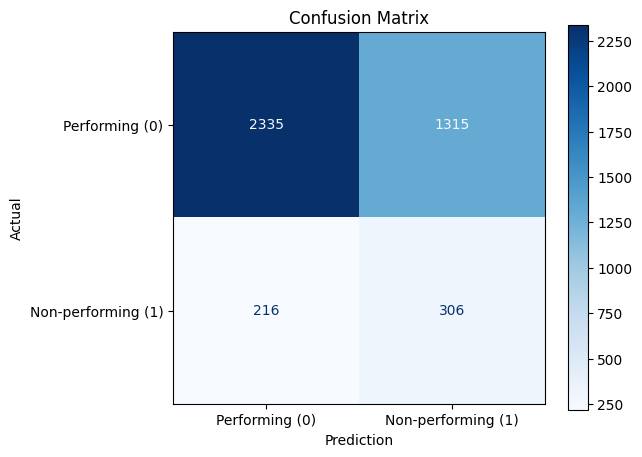

True Negative  : 2335
False Positive : 1315  <-- Lost Customers
False Negative : 216  <-- Bank Loss
True Positive  : 306


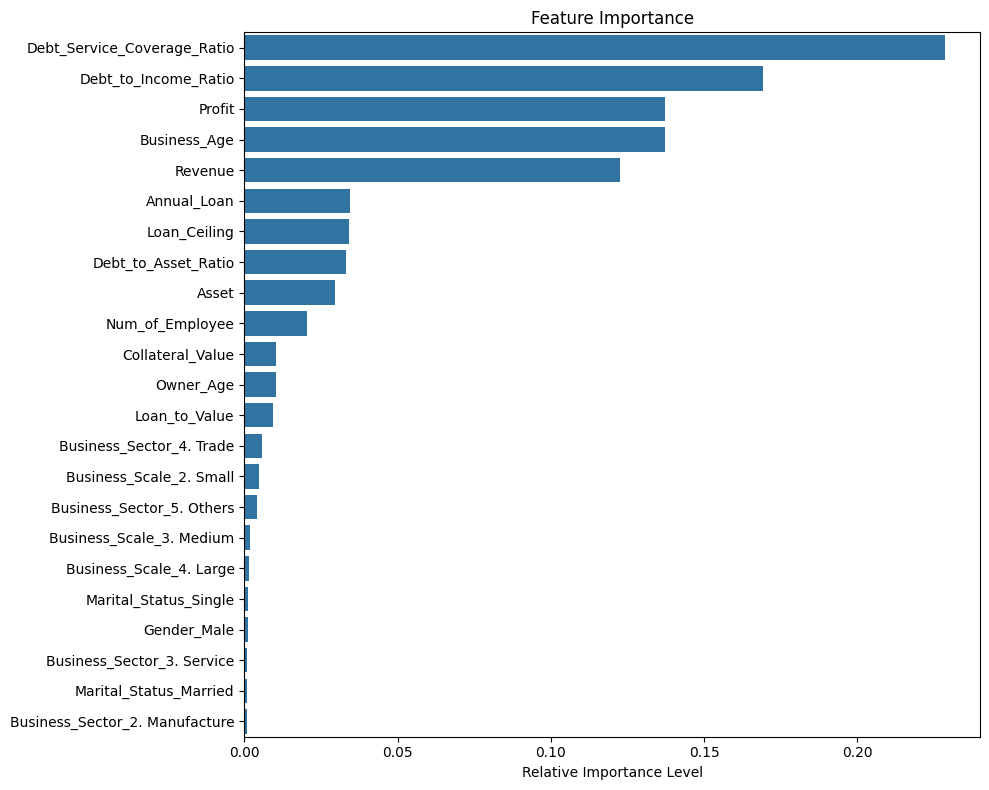

In [383]:
# Separate Feature (X) and Target (y)
X = df.drop(columns=['Customer_ID', 'Interest_Rate', 'Credit_Status'], errors='ignore')
y = df['Credit_Status']

# Define categorical columns
categorical_cols = ['Marital_Status', 'Gender', 'Business_Scale', 'Business_Sector']

# Create Preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

# Create Base Model
rf_base = RandomForestClassifier(
    n_estimators=75,
    class_weight='balanced',
    max_depth=4,
    random_state=42
)

calibrated_rf = CalibratedClassifierCV(estimator=rf_base, method='isotonic', cv=5)

# Create Pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', calibrated_rf)
])

# Fit Pipeline using training data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model_pipeline.fit(X_train, y_train)

# Save pipeline
joblib.dump(model_pipeline, 'credit_scoring_model.pkl')

# Evaluate the model
y_pred_proba = model_pipeline.predict_proba(X_test)[:, 1]
threshold = 0.12
y_pred_custom = (y_pred_proba >= threshold).astype(int)

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Display the Confusion Matrix
cm = confusion_matrix(y_test, y_pred_custom)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Performing (0)', 'Non-performing (1)'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax)
plt.ylabel('Actual')
plt.xlabel('Prediction')
plt.title('Confusion Matrix')
plt.show()

print(f"True Negative  : {cm[0][0]}")
print(f"False Positive : {cm[0][1]}  <-- Lost Customers")
print(f"False Negative : {cm[1][0]}  <-- Bank Loss")
print(f"True Positive  : {cm[1][1]}")

# Calculating Feature Importances
feature_name = model_pipeline.named_steps['preprocessor'].get_feature_names_out()
cleaned_feature_name = [f.split('__')[-1] for f in feature_name]
calibrated_clf = model_pipeline.named_steps['classifier']

# Calculate avg importance
importances = np.mean([
    clf.estimator.feature_importances_
    for clf in calibrated_clf.calibrated_classifiers_
], axis=0)

df_importance = pd.DataFrame({
    'Feature': cleaned_feature_name,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=df_importance)
plt.title('Feature Importance')
plt.xlabel('Relative Importance Level')
plt.ylabel('')
plt.tight_layout()
plt.show()

# 3. Calculating PD, Credit Score, EAD, LGD, and ECL

In [384]:
# Load pipeline
loaded_pipeline = joblib.load('credit_scoring_model.pkl')
X_full = df.drop(columns=['Customer_ID', 'Interest_Rate', 'Credit_Status'])

# Adding PD to the dataset
df['Probability_of_Default'] = loaded_pipeline.predict_proba(X_full)[:, 1]
df['Probability_of_Default'] = np.clip(df['Probability_of_Default'], 0.0001, 0.9999)

# Calculate Odds
df['Odds'] = (1 - df['Probability_of_Default']) / df['Probability_of_Default']

# Define Calibration Parameters
base_score = 600
base_odds = df['Odds'].median()
pdo = 100 / (np.log(df['Odds']).std())

# Calculate Factor & Offset values
factor = pdo / np.log(2)
offset = base_score - (factor * np.log(base_odds))

# Calculate Credit Score
df['Credit_Score'] = offset + (factor * np.log(df['Odds']))
df['Credit_Score'] = np.clip(np.round(df['Credit_Score']), 300, 850).astype(int)

# Calculate EAD
df['log_DSCR'] = np.log(df['Debt_Service_Coverage_Ratio'])
DSCR_min = df['log_DSCR'].min()
DSCR_max = df['log_DSCR'].max()
df['DSCR_norm'] = (df[['log_DSCR']] - DSCR_min)/(DSCR_max - DSCR_min)
df['EAD_Factor'] = 0.9 - df['DSCR_norm']*(0.9 - 0.4)
df['Exposure_At_Default'] = df['EAD_Factor'] * df['Loan_Ceiling']

# Calculate LGD percentage based on business scale
df['Loss_Given_Default'] = np.where(df['Business_Scale'].isin(['Mikro', 'Kecil']), 0.8, 0.4)

# Calculate ECL
df['Expected_Credit_Loss'] = df['Probability_of_Default'] * df['Exposure_At_Default'] * df['Loss_Given_Default']
df = df.drop(columns=['log_DSCR', 'DSCR_norm', 'EAD_Factor'])

# Save as csv
df.to_csv('MSME_credit_data_analyzed.csv', index=False)
df

,Customer_ID,Owner_Age,Marital_Status,Gender,Business_Scale,Business_Sector,Business_Age,Asset,Revenue,Profit,...,Annual_Loan,Debt_to_Asset_Ratio,Debt_to_Income_Ratio,Debt_Service_Coverage_Ratio,Probability_of_Default,Odds,Credit_Score,Exposure_At_Default,Loss_Given_Default,Expected_Credit_Loss
0,100001,60,Divorced,Female,4. Large,2. Manufacture,2,3.238028e+10,1.372559e+11,2.295496e+10,...,3.870997e+09,0.119548,0.028203,5.929986,0.121410,7.236547,557,5.671856e+09,0.4,2.754483e+08
1,100002,44,Divorced,Male,1. Micro,1. Culinary,4,2.931856e+08,3.839535e+08,6.658355e+07,...,8.487748e+06,0.028950,0.022106,7.844667,0.147691,5.770874,505,1.158470e+07,0.4,6.843844e+05
2,100003,23,Divorced,Female,4. Large,4. Trade,4,1.613097e+10,5.547279e+10,9.366117e+09,...,3.723349e+09,0.230820,0.067120,2.515509,0.199058,4.023656,421,6.701318e+09,0.4,5.335809e+08
3,100004,42,Married,Male,1. Micro,4. Trade,10,3.241326e+08,6.037758e+08,1.520011e+08,...,1.206730e+07,0.037230,0.019986,12.596112,0.105881,8.444572,593,1.849297e+07,0.4,7.832213e+05
4,100005,22,Divorced,Female,2. Small,2. Manufacture,4,1.186349e+09,1.304130e+10,2.575475e+09,...,2.190374e+08,0.184632,0.016796,11.758155,0.103092,8.700052,599,2.932537e+08,0.4,1.209287e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20855,120856,63,Divorced,Male,1. Micro,1. Culinary,14,2.092866e+08,1.180256e+09,2.916601e+08,...,2.147175e+07,0.102595,0.018192,13.583433,0.101086,8.892567,605,2.962005e+07,0.4,1.197669e+06
20856,120857,52,Single,Female,2. Small,4. Trade,18,4.281847e+09,7.740089e+09,1.144419e+09,...,1.882616e+08,0.043967,0.024323,6.078876,0.080553,11.414259,662,3.072521e+08,0.4,9.899973e+06
20857,120858,40,Married,Male,4. Large,4. Trade,9,4.900873e+10,5.975302e+10,9.004886e+09,...,3.490633e+09,0.071225,0.058418,2.579729,0.162819,5.141806,478,5.454572e+09,0.4,3.552422e+08
20858,120859,60,Divorced,Female,1. Micro,1. Culinary,4,5.545786e+07,1.642162e+09,2.751770e+08,...,1.176005e+07,0.212054,0.007161,23.399295,0.135805,6.363489,527,1.612598e+07,0.4,8.759964e+05
